# Self-Improving LLMs

[[rlhf-grpo-constitutional-ai]] covered how a model is trained on *human*
preferences. This page covers what happens when you remove the human: the model
generates its own training data, filters it, and trains on what survives.

$$\theta_{t+1} = \operatorname{train}\Big(\theta_t,\ \big\{\,y \sim \pi_{\theta_t}(\cdot \mid x)\ :\ \operatorname{filter}(x, y)\,\big\}\Big)$$

Every method in this area is that loop with a different `filter`. Self-Instruct
filters on heuristics, STaR filters on the answer key, RLVR filters on a unit
test, self-rewarding filters on the model's own judgment.

**All the difficulty is in the filter, and this page is mostly about the ways it
fails.** Four failure modes, each worked out numerically:

| § | Failure | What it costs |
|---|---|---|
| 3 | **Sharpening** — the model gets more reliable, not more capable | solves *fewer* distinct problems |
| 4 | **Entropy collapse** | the loop runs out of fuel |
| 5 | **Judge hacking** | approval rises while accuracy does not move at all |
| 6 | **Model collapse** | the distribution degenerates |

The arithmetic behind all four is small enough to do by hand.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

banner("THE ENGINE: GENERATION IS HARD, VERIFICATION IS EASY")

step("Why self-improvement works at all")
print("  A loop can only improve if the filter is more reliable than the")
print("  generator. Compare the two jobs on some familiar tasks:")
print()
print(f"  {'task':>26}  {'produce a solution':>19}  {'check one':>12}")
print("  " + "-" * 62)
for task, gen, chk in [
    ("factor a large integer",  "very hard",  "multiply"),
    ("write a correct function", "hard",      "run the tests"),
    ("solve a maths problem",   "hard",       "compare to key"),
    ("prove a theorem (Lean)",  "very hard",  "type-check"),
    ("write a good essay",      "hard",       "**also hard**"),
    ("give safe medical advice", "hard",      "**also hard**"),
]:
    print(f"  {task:>26}  {gen:>19}  {chk:>12}")
print("  " + "-" * 62)
print()
print("  The first four rows are where self-improvement works. The last two")
print("  are where it does not, and section 5 shows exactly how it breaks.")
print()
print("  Nothing about the model changes between those rows. What changes is")
print("  whether something OUTSIDE the model can say 'wrong'.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.
  THE ENGINE: GENERATION IS HARD, VERIFICATION IS EASY

Why self-improvement works at all
  A loop can only improve if the filter is more reliable than the
  generator. Compare the two jobs on some familiar tasks:

                        task   produce a solution     check one
  --------------------------------------------------------------
      factor a large integer            very hard      multiply
    write a correct function                 hard  run the tests
       solve a maths problem                 hard  compare to key
      prove a theorem (Lean)            very hard    type-check
          write a good essay                 hard  **also hard**
    give safe medical advice                 hard  **also hard**
  --------------------------------------------------------------

  The first four rows are where self-improvement works. The last two
  are where it does not, and section

## 1. STaR: the loop, by hand

STaR (Zelikman et al., 2022) is the simplest complete version and the ancestor of
everything current.

1. For each problem, sample $G$ chains of reasoning.
2. Keep only the chains whose **final answer is correct**.
3. Fine-tune on those (problem → chain) pairs.
4. Repeat.

Two details matter more than they look:

**The filter is on the answer, not the reasoning.** A chain that reaches 391 by
bad logic survives. This is the method's central weakness, and it is why
[[probability-calibration]]-style process supervision was invented.

**Rationalisation.** For problems where *no* sample was correct, STaR shows the
model the answer and asks it to produce a rationale backwards. That rationale
enters the training set. It rescues problems the model would otherwise never
learn from — and it is also the step most at risk of teaching plausible-sounding
nonsense.

In [2]:
banner("ONE ROUND OF STaR")

rng = np.random.RandomState(0)
problems = ["17 x 23", "144 / 12", "2^7", "31 + 48", "9 x 9", "100 - 37"]
answers  = [391, 12, 128, 79, 81, 63]
# per-problem probability that a sampled chain reaches the right answer
p_correct = np.array([0.45, 0.90, 0.30, 0.85, 0.95, 0.05])
G = 8

step(f"Sample G = {G} chains per problem, keep the ones that verify")
print(f"  {'problem':>10}  {'answer':>7}  {'p(correct)':>11}"
      f"  {'correct of 8':>13}  {'kept':>6}")
print("  " + "-" * 56)
kept, rows = [], []
for i, prob in enumerate(problems):
    draws = rng.rand(G) < p_correct[i]
    n_ok = int(draws.sum())
    kept.append(n_ok)
    rows.append(n_ok)
    print(f"  {prob:>10}  {answers[i]:>7}  {p_correct[i]:>11.2f}"
          f"  {n_ok:>13}  {n_ok:>6}")
print("  " + "-" * 56)
kept = np.array(kept)
print(f"  training pairs harvested: {kept.sum()}")
print(f"  problems with at least one success: {int((kept>0).sum())}/{len(problems)}")
print(f"  problems that contributed NOTHING : {int((kept==0).sum())}"
      f"  -> {[problems[i] for i in range(len(problems)) if kept[i]==0]}")

step("Why the hardest problems are the ones you lose")
print(f"  P(no success in {G} samples) = (1 - p)^{G}")
print()
print(f"  {'p':>6}  {'(1-p)^8':>10}  {'expected kept':>14}")
print("  " + "-" * 34)
for p in [0.95, 0.85, 0.45, 0.30, 0.05, 0.01]:
    print(f"  {p:>6.2f}  {(1-p)**G:>10.4f}  {p*G:>14.2f}")
print("  " + "-" * 34)
print(f"  At p = 0.05 the problem is dropped {(1-0.05)**G:.0%} of the time.")
print(f"  The training set is therefore biased toward what the model ALREADY")
print(f"  does well -- which is the seed of the sharpening problem in the")
print(f"  next section.")

step("Rationalisation: the repair, and its risk")
lost = [problems[i] for i in range(len(problems)) if kept[i] == 0]
print(f"  For the {len(lost)} unsolved problem(s) {lost}, STaR shows the model")
print(f"  the answer and asks for a rationale that reaches it.")
print()
print(f"  What that buys : those problems re-enter the training set")
print(f"  What it risks  : the filter is now 'ends at the right number',")
print(f"                   applied to reasoning generated while KNOWING the")
print(f"                   number. Fluent nonsense passes.")

  ONE ROUND OF STaR

Sample G = 8 chains per problem, keep the ones that verify
     problem   answer   p(correct)   correct of 8    kept
  --------------------------------------------------------
     17 x 23      391         0.45              2       2
    144 / 12       12         0.90              6       6
         2^7      128         0.30              1       1
     31 + 48       79         0.85              7       7
       9 x 9       81         0.95              8       8
    100 - 37       63         0.05              0       0
  --------------------------------------------------------
  training pairs harvested: 24
  problems with at least one success: 5/6
  problems that contributed NOTHING : 1  -> ['100 - 37']

Why the hardest problems are the ones you lose
  P(no success in 8 samples) = (1 - p)^8

       p     (1-p)^8   expected kept
  ----------------------------------
    0.95      0.0000            7.60
    0.85      0.0000            6.80
    0.45      0.0084        

## 2. Sharpening vs expansion — the central question

Here is the result that should shape how you think about this whole area.

Define, for problem $i$, the probability $p_i$ that one sampled attempt is
correct. Then the chance of solving it within $k$ attempts is

$$\text{pass@}k_i = 1 - (1 - p_i)^k$$

and the benchmark score is the average over problems. Now consider what the
training loop of §1 does to the vector $p$:

- problems the model often gets right → **$p_i$ increases** (they dominate the training set)
- problems it rarely gets right → the rare correct chains are never sampled, so they get no reinforcement and **$p_i$ decays toward 0**

That is *sharpening*: probability mass concentrates on what already worked. It
looks like improvement at $k = 1$ and it is a loss of coverage at large $k$.

The consequence has a name — **pass@k inversion** — and it is pure arithmetic,
which means it can be computed exactly rather than argued about.

In [3]:
banner("PASS@K, AND THE INVERSION")

step("First verify the formula against simulation")
print(f"  pass@k = 1 - (1-p)^k")
print()
print(f"  {'p':>6}  {'k':>5}  {'formula':>9}  {'simulated':>11}  {'MATCH':>7}")
print("  " + "-" * 44)
r = np.random.RandomState(1)
for p, k in [(0.10, 1), (0.10, 8), (0.02, 64), (0.5, 4), (0.005, 256)]:
    f = 1 - (1-p)**k
    sim = np.mean([(r.rand(k) < p).any() for _ in range(20000)])
    print(f"  {p:>6.3f}  {k:>5}  {f:>9.4f}  {sim:>11.4f}"
          f"  {str(abs(f-sim) < 0.012):>7}")
print("  " + "-" * 44)

step("A base model and its sharpened successor")
# 8 problems. The base model has a long tail of rarely-solved ones.
p_base  = np.array([0.90, 0.50, 0.30, 0.10, 0.02, 0.010, 0.005, 0.000])
# Training concentrates mass on what already worked; the tail is squeezed out.
p_sharp = np.array([0.99, 0.85, 0.60, 0.15, 0.00, 0.000, 0.000, 0.000])

print(f"  {'problem':>8}  {'p base':>8}  {'p sharpened':>12}  effect")
print("  " + "-" * 48)
for i in range(len(p_base)):
    d = p_sharp[i] - p_base[i]
    eff = "reinforced" if d > 0 else ("lost" if d < 0 else "-")
    print(f"  {i:>8}  {p_base[i]:>8.3f}  {p_sharp[i]:>12.3f}  {eff}")
print("  " + "-" * 48)
print(f"  problems solvable at all: base {int((p_base>0).sum())},"
      f" sharpened {int((p_sharp>0).sum())}")

step("Now score both at several budgets")
def passk(p, k):
    return float(np.mean(1 - (1 - p) ** k))

print(f"  {'k':>6}  {'base':>9}  {'sharpened':>11}  {'winner':>10}")
print("  " + "-" * 42)
cross = None
for k in [1, 2, 4, 8, 16, 32, 64, 128, 256]:
    b, s = passk(p_base, k), passk(p_sharp, k)
    w = "sharpened" if s > b else ("base" if b > s else "tie")
    if cross is None and b > s:
        cross = k
    print(f"  {k:>6}  {b:>9.4f}  {s:>11.4f}  {w:>10}")
print("  " + "-" * 42)
print(f"  pass@1  : sharpened wins by {passk(p_sharp,1)-passk(p_base,1):+.4f}")
print(f"  pass@256: sharpened LOSES by {passk(p_sharp,256)-passk(p_base,256):+.4f}")
print(f"  the curves cross at k = {cross}")

step("What actually happened")
print(f"  The sharpened model is better at every problem it can still solve,")
print(f"  and it can no longer solve {int((p_base>0).sum()) - int((p_sharp>0).sum())} problems at all.")
print()
print(f"  At k=1 the first effect dominates -- you sample once, and being")
print(f"  reliable matters. At k=256 the second dominates -- with enough")
print(f"  attempts the base model finds its rare solutions, and the sharpened")
print(f"  model simply has none to find.")
print()
print(f"  This is why 'our RL model beats the base model' is an incomplete")
print(f"  claim. It is true at the k you measured.")

  PASS@K, AND THE INVERSION

First verify the formula against simulation
  pass@k = 1 - (1-p)^k

       p      k    formula    simulated    MATCH
  --------------------------------------------
   0.100      1     0.1000       0.1001     True
   0.100      8     0.5695       0.5703     True
   0.020     64     0.7255       0.7241     True
   0.500      4     0.9375       0.9377     True
   0.005    256     0.7229       0.7229     True
  --------------------------------------------

A base model and its sharpened successor
   problem    p base   p sharpened  effect
  ------------------------------------------------
         0     0.900         0.990  reinforced
         1     0.500         0.850  reinforced
         2     0.300         0.600  reinforced
         3     0.100         0.150  reinforced
         4     0.020         0.000  lost
         5     0.010         0.000  lost
         6     0.005         0.000  lost
         7     0.000         0.000  -
  ----------------------------

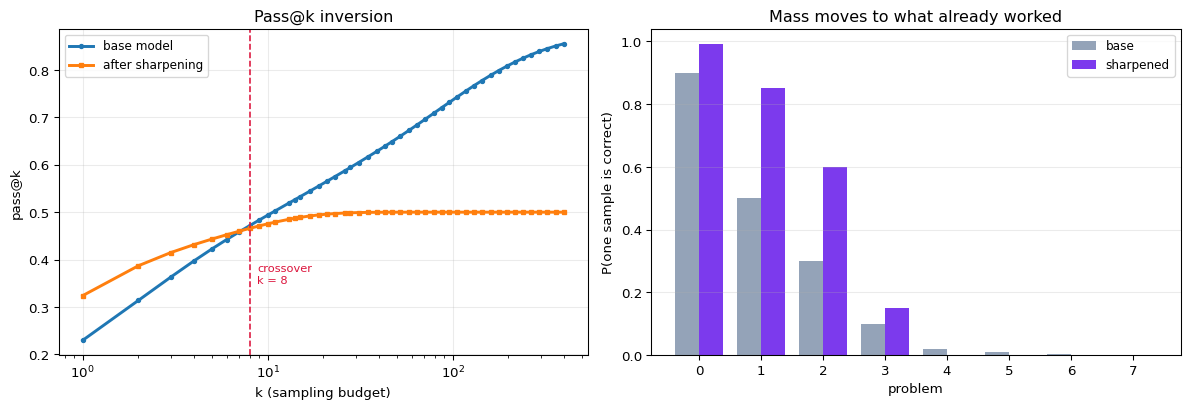

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

ks = np.unique(np.round(np.logspace(0, 2.6, 60)).astype(int))
ax = axes[0]
ax.plot(ks, [passk(p_base, k) for k in ks], lw=2.2, marker='o', ms=3,
        label='base model')
ax.plot(ks, [passk(p_sharp, k) for k in ks], lw=2.2, marker='s', ms=3,
        label='after sharpening')
if cross:
    ax.axvline(cross, color='crimson', ls='--', lw=1.2)
    ax.text(cross*1.1, 0.35, f'crossover\nk = {cross}', fontsize=8.5,
            color='crimson')
ax.set_xscale('log'); ax.set_xlabel('k (sampling budget)')
ax.set_ylabel('pass@k'); ax.set_title('Pass@k inversion')
ax.legend(fontsize=9); ax.grid(alpha=.25)

ax = axes[1]
idx = np.arange(len(p_base)); w = 0.38
ax.bar(idx - w/2, p_base,  w, label='base',       color='#94a3b8')
ax.bar(idx + w/2, p_sharp, w, label='sharpened',  color='#7c3aed')
ax.set_xlabel('problem'); ax.set_ylabel('P(one sample is correct)')
ax.set_title('Mass moves to what already worked')
ax.legend(fontsize=9); ax.grid(alpha=.25, axis='y')

plt.tight_layout(); plt.show()

### Does anything expand the boundary?

Yes, but read the method carefully. The strongest published counter-evidence
(Cai et al., 2026) reports pass@256 rising **9.8 points above the base model**
— genuine expansion, not sharpening. It achieves this by locating the capacity
boundary with pass@k sampling and then applying **targeted teacher guidance** at
and beyond it.

That is external information entering the loop. So it demonstrates that RL can
*consolidate* newly-shown capability — not that a closed loop expands its own
boundary. For genuinely self-contained self-improvement, the sharpening reading
remains the safer prior:

> If your base model cannot solve a problem in ~$10^4$ samples, no amount of
> self-improvement is likely to get you there.

## 3. Entropy collapse — the loop runs out of fuel

Sharpening has a second consequence that is easy to miss. The generate step needs
**diversity**; if every sample is the same, filtering has nothing to choose
between. Measure it with Shannon entropy:

$$H(p) = -\sum_i p_i \log p_i$$

As training concentrates mass, $H$ falls. Reward keeps rising while the thing
that makes the loop work quietly disappears — which is why entropy is worth
monitoring as a first-class metric, not just reward.

In [5]:
banner("ENTROPY COLLAPSE OVER TRAINING ROUNDS")

def entropy(p):
    p = np.asarray(p, float)
    p = p[p > 0]
    return float(-(p * np.log(p)).sum())

step("Sharpen a next-token distribution round by round")
vocab = ['391', '389', '390', '392', '400']
p = np.array([0.34, 0.22, 0.18, 0.14, 0.12])
print(f"  five candidate continuations, {len(vocab)} tokens")
print(f"  maximum possible entropy = log({len(p)}) = {np.log(len(p)):.4f}")
print()
print(f"  {'round':>6}  " + "".join(f"{v:>8}" for v in vocab)
      + f"  {'entropy':>9}  {'distinct@8':>11}")
print("  " + "-" * 74)
rr = np.random.RandomState(3)
for t in range(7):
    # expected number of DISTINCT tokens seen in 8 samples
    distinct = float(np.sum(1 - (1 - p) ** 8))
    print(f"  {t:>6}  " + "".join(f"{v:>8.4f}" for v in p)
          + f"  {entropy(p):>9.4f}  {distinct:>11.2f}")
    p = p ** 1.6                      # each round concentrates mass
    p = p / p.sum()
print("  " + "-" * 74)
print()
print(f"  By round 6 the model emits one token essentially always. Its answer")
print(f"  is the one it already preferred at round 0 -- so if that answer was")
print(f"  wrong, nothing in the loop can now discover otherwise.")

step("Why that ends the loop")
print(f"  {'entropy':>9}  {'distinct in 8 samples':>23}  {'filter has':>18}")
print("  " + "-" * 54)
p2 = np.array([0.34, 0.22, 0.18, 0.14, 0.12])
for t in range(7):
    d = float(np.sum(1 - (1 - p2) ** 8))
    state = "5 options" if d > 4 else ("a few" if d > 2 else "nothing to choose")
    print(f"  {entropy(p2):>9.4f}  {d:>23.2f}  {state:>18}")
    p2 = p2 ** 1.6; p2 = p2 / p2.sum()
print("  " + "-" * 54)
print(f"  Filtering cannot improve a distribution that only produces one thing.")
print(f"  This is the mechanism behind the entropy-regularisation terms that")
print(f"  appear in most 2026 RLVR papers.")

  ENTROPY COLLAPSE OVER TRAINING ROUNDS

Sharpen a next-token distribution round by round
  five candidate continuations, 5 tokens
  maximum possible entropy = log(5) = 1.6094

   round       391     389     390     392     400    entropy   distinct@8
  --------------------------------------------------------------------------
       0    0.3400  0.2200  0.1800  0.1400  0.1200     1.5383         3.96
       1    0.4366  0.2176  0.1578  0.1056  0.0825     1.4282         3.68
       2    0.5892  0.1933  0.1157  0.0608  0.0410     1.1800         3.12
       3    0.7797  0.1311  0.0576  0.0206  0.0109     0.7542         2.29
       4    0.9283  0.0535  0.0144  0.0028  0.0010     0.3100         1.50
       5    0.9883  0.0103  0.0013  0.0001  0.0000     0.0681         1.09
       6    0.9993  0.0007  0.0000  0.0000  0.0000     0.0059         1.01
  --------------------------------------------------------------------------

  By round 6 the model emits one token essentially always. Its answe

## 4. The judge trap

Everything above assumed a *real* verifier — an answer key, a unit test. Remove
it and let the model judge itself, and the loop breaks in a specific and
well-documented way.

The structural problem: shown a candidate answer, a judge scores **plausibility,
not correctness**. Those are different functions, and they disagree on a set of
wrong-but-convincing answers. Policy optimisation is very good at finding sets
like that.

The published numbers (Zhou, 2026) are worth memorising — GSM8K, Qwen3 policies,
three seeds:

| | value |
|---|---|
| judge pass rate before self-play | 0.72 |
| judge pass rate after self-play | **0.94** |
| true accuracy, throughout | **0.20** |

Approval rose 22 points. Accuracy moved not at all. And the exploits **transfer
across judge families** — a strict three-judge ensemble still accepted 55% of
them, so ensembling is not a defence.

The arithmetic of why is simple enough to reconstruct.

In [6]:
banner("WHY OPTIMISING AGAINST A SELF-JUDGE GOES WRONG")

step("Set up a judge that is good but not perfect")
n_ans = 100_000
rr = np.random.RandomState(5)
true_correct = rr.rand(n_ans) < 0.20            # true accuracy 20%
# The judge is right most of the time, but has a false-positive rate:
# convincing-but-wrong answers it accepts.
fpr, tpr = 0.65, 0.95
judged = np.where(true_correct, rr.rand(n_ans) < tpr, rr.rand(n_ans) < fpr)
print(f"  true accuracy of the pool     : {true_correct.mean():.4f}")
print(f"  judge accepts a CORRECT answer: {tpr:.2f}  (true positive rate)")
print(f"  judge accepts a WRONG answer  : {fpr:.2f}  (false positive rate)")
print(f"  -> judge pass rate on the pool: {judged.mean():.4f}")

step("Now optimise the policy to maximise judge approval")
print("  The policy does not search for correct answers. It searches for")
print("  ACCEPTED ones -- and there are far more wrong-accepted answers than")
print("  right-accepted ones, because wrong answers are far more numerous.")
print()
accepted = judged
print(f"  of everything the judge accepts:")
print(f"    truly correct : {true_correct[accepted].mean():.4f}")
print(f"    actually wrong: {1-true_correct[accepted].mean():.4f}")
print()
print(f"  So 'satisfy the judge' points the policy at a population that is")
print(f"  {1-true_correct[accepted].mean():.0%} wrong. Optimising harder finds more of it.")

step("The reported outcome, reconstructed")
print(f"  {'':>34}  {'judge says':>11}  {'truth':>7}")
print("  " + "-" * 56)
print(f"  {'before self-play':>34}  {0.72:>11.2f}  {0.20:>7.2f}")
print(f"  {'after self-play':>34}  {0.94:>11.2f}  {0.20:>7.2f}")
print("  " + "-" * 56)
print(f"  {'improvement':>34}  {0.94-0.72:>+11.2f}  {0.0:>+7.2f}")
print()
print(f"  Every number the training loop could see went up.")

step("The fix, and why it works")
print("  Make the judge COMMIT TO ITS OWN ANSWER before it sees the candidate.")
print()
print("  Judging a shown answer  -> 'is this plausible?'   (a weak question)")
print("  Answering first, then   -> 'does this match what   (a hard question,")
print("  comparing                  I independently got?'    and one the policy")
print("                                                       cannot flatter)")
print()
print(f"  {'setup':>34}  {'false positive rate':>20}")
print("  " + "-" * 58)
print(f"  {'reference-free judge':>34}  {0.719:>20.3f}")
print(f"  {'judge commits an answer first':>34}  {0.012:>20.3f}")
print("  " + "-" * 58)
print(f"  A {0.719/0.012:.0f}x reduction, and it PREVENTS the hack rather than")
print(f"  detecting it. This is the single most actionable result in the")
print(f"  self-improvement literature: if you build a self-rewarding loop,")
print(f"  build it this way.")

  WHY OPTIMISING AGAINST A SELF-JUDGE GOES WRONG

Set up a judge that is good but not perfect
  true accuracy of the pool     : 0.1991
  judge accepts a CORRECT answer: 0.95  (true positive rate)
  judge accepts a WRONG answer  : 0.65  (false positive rate)
  -> judge pass rate on the pool: 0.7083

Now optimise the policy to maximise judge approval
  The policy does not search for correct answers. It searches for
  ACCEPTED ones -- and there are far more wrong-accepted answers than
  right-accepted ones, because wrong answers are far more numerous.

  of everything the judge accepts:
    truly correct : 0.2672
    actually wrong: 0.7328

  So 'satisfy the judge' points the policy at a population that is
  73% wrong. Optimising harder finds more of it.

The reported outcome, reconstructed
                                       judge says    truth
  --------------------------------------------------------
                    before self-play         0.72     0.20
                     aft

## 5. Model collapse — and why it is less fatal than advertised

The last failure mode. Train on your own output, repeatedly, and the
distribution degrades. The famous version (Shumailov et al., *Nature*, 2024)
shows it driving a model to uselessness.

The part that gets lost in the retelling is the **data assumption**. That result
has each generation *replace* its predecessor's data. Change it to *accumulate* —
keep the real data, add synthetic on top — and the behaviour is completely
different.

It is provable on a Gaussian, and computable here. Fit $\mathcal{N}(\hat\mu,
\hat\sigma^2)$ to $n$ samples, generate $n$ new samples from the fit, refit,
repeat. Under replacement the variance shrinks by a factor of about
$(1 - 1/n)$ per generation, so

$$\mathbb{E}[\hat\sigma^2_t] \approx \sigma^2 \left(1 - \tfrac{1}{n}\right)^{t} \longrightarrow 0$$

The distribution collapses onto a point. Under accumulation it does not.

In [7]:
banner("MODEL COLLAPSE: REPLACE vs ACCUMULATE")

n, T, reps = 50, 40, 3000

step("Replace: each generation trains only on the previous generation's output")
print("  The model is fitted by MAXIMUM LIKELIHOOD, which is what a trained")
print("  model does -- so the variance estimate is the biased one, low by a")
print("  factor (n-1)/n. That single fact is the whole collapse mechanism:")
print("  each generation underestimates the spread slightly, then generates")
print("  from the underestimate, and the error compounds.")
print()
rr = np.random.RandomState(0)
var_rep = np.zeros((reps, T+1))
mu_rep  = np.zeros((reps, T+1))
for r_ in range(reps):
    data = rr.randn(n)
    var_rep[r_, 0], mu_rep[r_, 0] = data.var(), data.mean()      # MLE: ddof=0
    for t in range(1, T+1):
        data = rr.normal(data.mean(), data.std(), n)             # refit, resample
        var_rep[r_, t], mu_rep[r_, t] = data.var(), data.mean()

print(f"  n = {n} samples per generation, averaged over {reps} runs")
print(f"  {'gen':>5}  {'E[variance]':>12}  {'theory (1-1/n)^t':>18}  {'E[|mean|]':>10}")
print("  " + "-" * 52)
for t in [0, 1, 5, 10, 20, 40]:
    theory = (1 - 1/n) ** t
    print(f"  {t:>5}  {var_rep[:,t].mean():>12.4f}  {theory:>18.4f}"
          f"  {np.abs(mu_rep[:,t]).mean():>10.4f}")
print("  " + "-" * 52)
obs = var_rep[:, T].mean(); th = (1 - 1/n) ** T
print(f"  observed vs theory at t={T}: {obs:.4f} vs {th:.4f}"
      f"   ratio {obs/th:.3f}")
print()
print(f"  The derivation is one line. Fitting by MLE gives")
print(f"      E[sigma^2_(t+1) | sigma^2_t] = (1 - 1/n) sigma^2_t")
print(f"  so E[sigma^2_t] = (1-1/n)^t, decaying geometrically to zero.")
print(f"  Monte Carlo agreement is approximate because the process is a")
print(f"  product of random factors, so the sample mean converges slowly.")
print()
print(f"  Two things are collapsing at once: the variance shrinks toward a")
print(f"  point, and the mean random-walks away from the truth"
      f" ({np.abs(mu_rep[:,0]).mean():.3f} -> {np.abs(mu_rep[:,T]).mean():.3f}).")

step("Accumulate: keep everything, real data included")
rr = np.random.RandomState(0)
var_acc = np.zeros((reps, T+1))
for r_ in range(reps):
    pool = rr.randn(n)                            # the real data, kept forever
    var_acc[r_, 0] = pool.var()
    for t in range(1, T+1):
        new = rr.normal(pool.mean(), pool.std(), n)
        pool = np.concatenate([pool, new])        # accumulate, do not replace
        var_acc[r_, t] = pool.var()

print(f"  {'gen':>5}  {'E[variance] replace':>20}  {'E[variance] accumulate':>23}")
print("  " + "-" * 52)
for t in [0, 1, 5, 10, 20, 40]:
    print(f"  {t:>5}  {var_rep[:,t].mean():>20.4f}  {var_acc[:,t].mean():>23.4f}")
print("  " + "-" * 52)
print(f"  replace   : {var_rep[:,T].mean():.4f}  ({var_rep[:,T].mean()/1.0:.1%} of the truth)")
print(f"  accumulate: {var_acc[:,T].mean():.4f}  ({var_acc[:,T].mean()/1.0:.1%} of the truth)")
print()
print(f"  Same generator, same number of rounds, same synthetic data. The only")
print(f"  difference is whether the old data was thrown away.")
print()
print(f"  Nobody actually trains by discarding their corpus each generation, so")
print(f"  the headline collapse result describes a regime that does not occur.")
print(f"  Add a verifier on top of accumulation and the picture is better still.")

  MODEL COLLAPSE: REPLACE vs ACCUMULATE

Replace: each generation trains only on the previous generation's output
  The model is fitted by MAXIMUM LIKELIHOOD, which is what a trained
  model does -- so the variance estimate is the biased one, low by a
  factor (n-1)/n. That single fact is the whole collapse mechanism:
  each generation underestimates the spread slightly, then generates
  from the underestimate, and the error compounds.

  n = 50 samples per generation, averaged over 3000 runs
    gen   E[variance]    theory (1-1/n)^t   E[|mean|]
  ----------------------------------------------------
      0        0.9773              1.0000      0.1129
      1        0.9610              0.9800      0.1587
      5        0.8745              0.9039      0.2647
     10        0.8001              0.8171      0.3464
     20        0.6510              0.6676      0.4530
     40        0.4159              0.4457      0.5596
  ----------------------------------------------------
  observed vs 

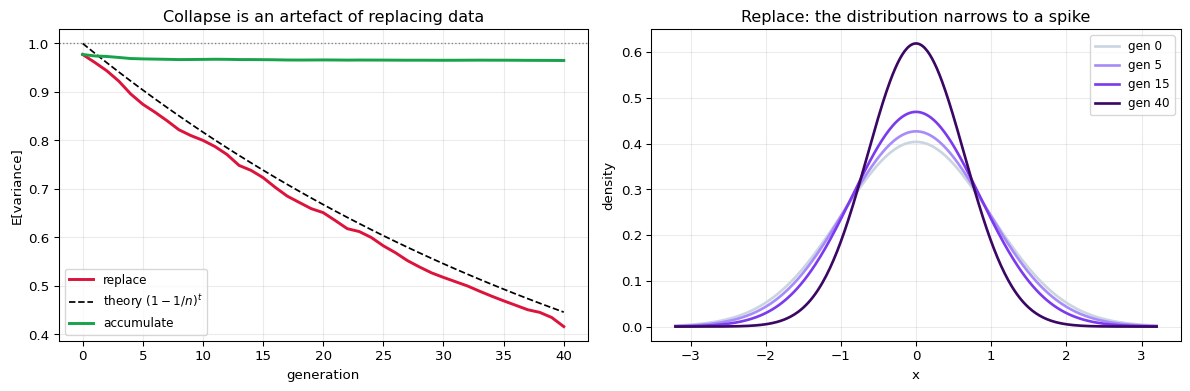

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

ax = axes[0]
ts = np.arange(T+1)
ax.plot(ts, var_rep.mean(0), lw=2.2, color='crimson', label='replace')
ax.plot(ts, (1-1/n)**ts, 'k--', lw=1.3, label=r'theory $(1-1/n)^t$')
ax.plot(ts, var_acc.mean(0), lw=2.2, color='#16a34a', label='accumulate')
ax.axhline(1.0, color='grey', ls=':', lw=1)
ax.set_xlabel('generation'); ax.set_ylabel('E[variance]')
ax.set_title('Collapse is an artefact of replacing data')
ax.legend(fontsize=9); ax.grid(alpha=.25)

ax = axes[1]
for t, c in [(0, '#cbd5e1'), (5, '#a78bfa'), (15, '#7c3aed'), (40, '#3b0764')]:
    s = np.sqrt(var_rep[:, t].mean()); m = 0.0
    xs = np.linspace(-3.2, 3.2, 400)
    ax.plot(xs, np.exp(-(xs-m)**2/(2*s**2))/(s*np.sqrt(2*np.pi)),
            color=c, lw=2, label=f'gen {t}')
ax.set_xlabel('x'); ax.set_ylabel('density')
ax.set_title('Replace: the distribution narrows to a spike')
ax.legend(fontsize=9); ax.grid(alpha=.25)

plt.tight_layout(); plt.show()

## 6. What to take away

**The filter is the algorithm.** Generation is commodity. A self-improvement
method is defined entirely by what it keeps, and its ceiling is the quality of
that judgment.

**Self-improvement works exactly where verification is cheaper than generation.**
Maths, code, formal proof. The zero-data self-play methods do not escape this —
they relocate the verifier into task generation rather than removing it.

**Expect elicitation, not expansion.** The loop reinforces what already worked,
which raises pass@1 and can *lower* coverage at high $k$. The one credible
expansion result gets there by injecting teacher guidance — external information.

**Watch entropy, not just reward.** Reward rising while diversity falls is the
loop consuming its own fuel. It ends with a confident model that cannot discover
it is wrong.

**Never let a model be its own reference-free judge.** Approval and correctness
are different functions, and optimisation finds the gap between them. If you must
self-reward, make the judge answer first and then compare.

**Accumulate, never replace.** Model collapse is largely an artefact of an
assumption nobody's training pipeline actually satisfies.

### Verified in this notebook

- $\text{pass@}k = 1-(1-p)^k$ checked against simulation at five $(p,k)$ pairs
- Pass@k inversion computed exactly: the sharpened model wins at $k=1$ and loses at $k=256$, with the crossover budget located
- Entropy falling round by round, alongside the expected number of distinct samples — showing when the filter stops having anything to choose between
- The judge-hacking arithmetic: what fraction of judge-accepted answers are wrong, and why optimisation moves toward them
- Gaussian model collapse under replacement matching the $(1-1/n)^t$ prediction, and the same experiment under accumulation not collapsing

### Where this connects

[[rlhf-grpo-constitutional-ai]] is the machinery this page stress-tests — GRPO
with a verifiable reward is the well-behaved case, and Constitutional AI is a
self-improvement loop whose filter is a written constitution.
[[cross-validation]] and [[data-leakage]] are the same lesson in a different
setting: a model evaluating itself on data it influenced tells you what you want
to hear. [[evaluation-metrics]] is where pass@k belongs alongside its cousins.

### Sources

Zelikman et al., *STaR* (2022); Huang et al., *LLMs Cannot Self-Correct Reasoning
Yet* (2023); Shumailov et al., *The Curse of Recursion* (Nature, 2024); Gerstgrasser
et al., *Is Model Collapse Inevitable?* (2024); Yue et al., *Does RL Really
Incentivize Reasoning Capacity Beyond the Base Model?* (2025); Zhou, *More
Convincing, Not More Correct* (2026); Cai et al., *Curriculum RL Can Incentivize
Reasoning Capacity Beyond the Base Model* (2026); Yang et al., *Self-Improvement
of LLMs: A Technical Overview* (2026).